In [85]:
#ROC-AUC Curve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
y_true = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0,
          1, 1, 0, 1, 0, 0, 1, 0, 1, 0]

y_pred = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0,
          0, 1, 0, 1, 1, 0, 1, 0, 0, 0]

In [6]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true,y_pred)
cm

array([[8, 2],
       [3, 7]])

In [7]:
class MyLearn:
    def __init__(self):
        self.__TPR=0
        self.__FPR=0
    
    def create_matrix(self,y_true,y_pred):
        df=pd.DataFrame()
        df["y_true"]=y_true
        df["y_pred"]=y_pred
        TP=df[(df['y_true']==1) & (df['y_pred']==1)].shape[0]
        FP=df[(df['y_true']==0) & (df['y_pred']==1)].shape[0]
        FN=df[(df['y_true']==1) & (df['y_pred']==0)].shape[0]
        TN=df[(df['y_true']==0) & (df['y_pred']==0)].shape[0]
        matrix=pd.DataFrame(
        [
            [TN,FP],
            [FN,TP]
        ],
        index=['Actual 0','Actual 1'],
        columns=['Predicted 0','Predicted 1']
        )
        self.__TPR=TP/(TP+FN)
        self.__FPR=FP/(FP+TN)
        return matrix
    def get_attr(self):
        return {'TPR':self.__TPR,'FPR':self.__FPR}
obj=MyLearn()
obj.create_matrix(y_true,y_pred)

,Predicted 0,Predicted 1
Actual 0,8,2
Actual 1,3,7


In [8]:
obj.get_attr()

{'TPR': 0.7, 'FPR': 0.2}

In [149]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve,roc_auc_score
from sklearn.svm import SVC

In [150]:
data=load_breast_cancer()
df=pd.DataFrame(data.data,columns=data.feature_names)
df['target']=data.target

X=df.iloc[:,0:-1]
y=df.iloc[:,-1:]
X_train, X_test ,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [151]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [152]:
y_train=y_train.values.ravel()
y_test=y_test.values.ravel()

In [153]:
# Logistic Regression 
lr=LogisticRegression()
lr.fit(X_train_scaled,y_train)
lr_scores=lr.predict_proba(X_test_scaled)
lr_scores=lr_scores[:,1]

# SVM
svm_model = SVC(probability=True)
svm_model.fit(X_train_scaled, y_train)
svm_scores = svm_model.predict_proba(X_test_scaled)[:,1]

D:\Python\envs\dsmp\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [154]:
# Generate ROC curve data for logistic regression model
lr_fpr, lr_tpr, lr_thresholds = roc_curve(y_test, lr_scores)
lr_auc = roc_auc_score(y_test, lr_scores)

# Generate ROC curve data for SVM model
svm_fpr, svm_tpr, svm_thresholds = roc_curve(y_test, svm_scores)
svm_auc = roc_auc_score(y_test, svm_scores)

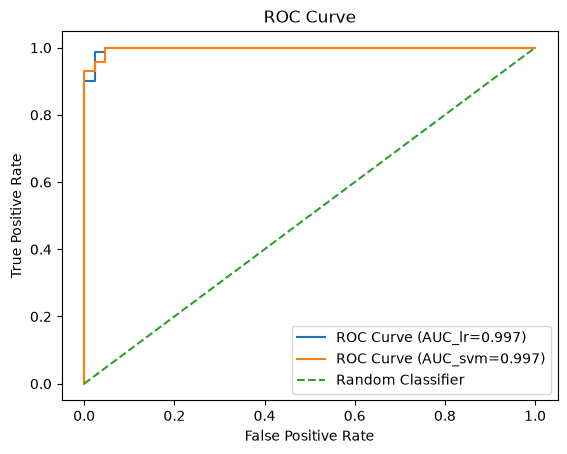

In [155]:
# Plot ROC curve
plt.plot(lr_fpr, lr_tpr, label=f"ROC Curve (AUC_lr={lr_auc:.3f})")
plt.plot(svm_fpr, svm_tpr, label=f"ROC Curve (AUC_svm={svm_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

In [167]:
optimal_idx = np.argmax(svm_tpr - svm_fpr)
svm_optimal_threshold = svm_thresholds[optimal_idx]
print("Optimal threshold for svm is:", svm_optimal_threshold)


optimal_idx = np.argmax(lr_tpr - lr_fpr)
lr_optimal_threshold = lr_thresholds[optimal_idx]
print("Optimal threshold for lr is:", lr_optimal_threshold)

Optimal threshold for svm is: 0.3967551851509126
Optimal threshold for lr is: 0.6206578599836928
